# La ville cachée

Le simulateur est la réalité du jeu. Il est volontairement plus riche que le modèle qu'on ajustera ensuite. Sinon l'inférence serait trop facile : elle connaîtrait déjà le mécanisme qui a produit les données.

Trois idées à garder séparées.

1. **L'état infectieux**, jamais publié : susceptible, exposé, infectieux (asymptomatique, présymptomatique, symptomatique), hôpital, soins intensifs, guéri, décès.
2. **Le dépistage** : non testé, testé négatif, testé positif. Un faux négatif reste contagieux et ne déclenche pas l'isolement.
3. **Les paramètres secrets**, tirés une fois dans les plages des consignes, puis cachés. Le modèle d'inférence ne lit pas `data/generated/.truth.json`. On les affiche ici seulement pour comprendre la ville.

Le notebook précédent montrait les 71 jours du cours. Ici on fabrique une ville courte, pour voir ce que le fichier publié ne contient pas.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

# Le notebook est dans notebooks/. On remonte à la racine du dépôt.
RACINE = Path.cwd().resolve()
if not (RACINE / "pyproject.toml").exists():
    RACINE = RACINE.parent
sys.path.insert(0, str(RACINE / "src"))

%matplotlib inline
pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 120)
pd.set_option("display.max_colwidth", 80)


## Cinq âges, quatre lieux

Les matrices de contact viennent de `data/external/stats/`. Une personne a des contacts à la maison, à l'école, au travail et dans le reste de la ville. L'école s'arrête après 17 ans : le groupe 70+ n'a aucun contact scolaire.


In [2]:
from epidemic.config import load_simulator_config
from epidemic.simulator.contacts import build_contacts

contacts = build_contacts(load_simulator_config())
print(f"Population : {contacts.population:,}".replace(",", " "))
print(f"Taille moyenne d'un ménage : {contacts.mean_household_size:.2f}")
print(f"Contacts pondérés moyens : {contacts.mean_weighted_contacts():.2f}")
print()
for groupe in contacts.groups:
    print(
        f"{groupe.name:6} {groupe.population:8d} habitants"
        f"   école {groupe.school_share:.0%}   travail {groupe.work_share:.0%}"
    )
print()
print("Contacts effectifs moyens par lieu :")
for lieu, degre in contacts.degrees.items():
    print(f"  {lieu:12} {degre:.2f}")


Population : 1 000 000
Taille moyenne d'un ménage : 2.54
Contacts pondérés moyens : 7.33

0-17     218365 habitants   école 78%   travail 0%
18-49    485323 habitants   école 0%   travail 70%
50-59    124111 habitants   école 0%   travail 70%
60-69     86990 habitants   école 0%   travail 41%
70+       85211 habitants   école 0%   travail 0%

Contacts effectifs moyens par lieu :
  home         2.50
  school       15.00
  work         12.84
  community    4.00


## Quatre niveaux de hasard

Chaque niveau ajoute une source d'aléa au précédent. La même graine redonne la même trajectoire à un niveau donné, et les paramètres secrets ne dépendent pas du niveau. On peut donc comparer une décision sur la même épidémie.

| Niveau | Nom | Ce qui varie |
|---|---|---|
| 0 | Déterministe | Les équations moyennes. Utile pour les tests. |
| 1 | Démographique | Qui est infecté, testé, hospitalisé est tiré au sort. |
| 2 | Environnementale | Le taux de contact, le dépistage et la sensibilité bougent un peu d'un jour à l'autre. |
| 3 | Individuelle | Contagiosité très inégale, respect des mesures variable, durées en gamma. |

Le niveau 1 est le défaut du développement. Le niveau 2 est le défaut du jeu. Les niveaux 2 et 3 restent modérés : la ville doit être un peu imprévisible, pas chaotique.


## Une trajectoire, et ce qu'elle cache

Quarante jours, graine 7, niveau 1. À gauche, les cas confirmés restent sous les nouvelles infections : le publié est une fraction du caché. À droite, les tests dépassent largement les cas. Une part porte sur des personnes non infectées, le fond de syndromes grippaux. Sur cette graine, l'hôpital bouge à peine en quarante jours : le pic de lits se voit mieux dans le notebook de la décision, sur une vague volontairement plus forte.


In [3]:
from epidemic.simulator import RealitySimulator

observations, cache = RealitySimulator.from_configs(seed=7, level=1).run(40)
print(observations.head(3).to_string(index=False))
print()
print(
    f"Infections cachées : {int(cache['new_infections'].sum())}. "
    f"Cas confirmés : {int(observations['num_positive'].sum())}. "
    f"Faux négatifs : {int(cache['false_negatives'].sum())}."
)


 Day  num_positive  num_tested  num_hospitalised  num_cumulative_hospitalizations  num_critical  num_fatalities
   1             0         469                 0                                0             0               0
   2             1         424                 0                                0             0               0
   3             0         433                 0                                0             0               0

Infections cachées : 168. Cas confirmés : 42. Faux négatifs : 17.


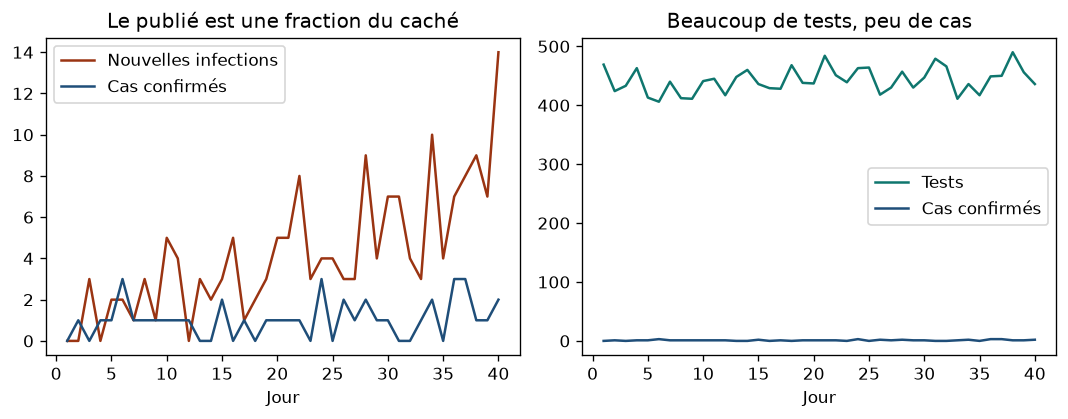

In [4]:
figure, axes = plt.subplots(1, 2, figsize=(9, 3.6))
axes[0].plot(cache["Day"], cache["new_infections"], color="#9a3412", label="Nouvelles infections")
axes[0].plot(observations["Day"], observations["num_positive"], color="#1f4e79", label="Cas confirmés")
axes[0].set_title("Le publié est une fraction du caché")
axes[0].set_xlabel("Jour")
axes[0].legend()

axes[1].plot(observations["Day"], observations["num_tested"], color="#0f766e", label="Tests")
axes[1].plot(observations["Day"], observations["num_positive"], color="#1f4e79", label="Cas confirmés")
axes[1].set_title("Beaucoup de tests, peu de cas")
axes[1].set_xlabel("Jour")
axes[1].legend()
figure.tight_layout()


## La graine fixe l'épidémie, pas le fichier publié

Deux appels avec la même graine et le même niveau donnent le même tableau. Changer de niveau change les tirages du jour, pas les paramètres tirés au départ (durée d'incubation, fraction symptomatique, β par contact).


In [5]:
premiere, _ = RealitySimulator.from_configs(seed=3, level=1).run(15)
seconde, _ = RealitySimulator.from_configs(seed=3, level=1).run(15)
print("Même graine, même niveau, mêmes cas :", premiere.equals(seconde))

calme = RealitySimulator.from_configs(seed=3, level=0)
agite = RealitySimulator.from_configs(seed=3, level=2)
print("Même β de départ :", calme.truth.beta_per_contact == agite.truth.beta_per_contact)
print("Niveau 0 :", calme.truth.sources)
print("Niveau 2 :", agite.truth.sources)


Même graine, même niveau, mêmes cas : True
Même β de départ : True
Niveau 0 : SourceFlags(demographic=False, environmental=False, individual_contagion=False, individual_compliance=False, individual_durations=False)
Niveau 2 : SourceFlags(demographic=True, environmental=True, individual_contagion=False, individual_compliance=False, individual_durations=False)


## Les paramètres qu'il ne faut pas donner au modèle

La cellule suivante les imprime pour cette graine. Dans une vraie analyse, on s'arrête aux colonnes de `data.csv`. Les priors du notebook suivant remplacent cette connaissance : on sait par exemple que l'incubation dure entre 1 et 5 jours, pas qu'elle vaut 2,4 jours dans cette ville.


In [6]:
ville = RealitySimulator.from_configs(seed=7, level=1)
secret = ville.truth
print(f"Fraction symptomatique     {secret.symptomatic_fraction:.2f}")
print(f"Sensibilité des tests      {secret.sensitivity:.2f}")
print(f"Part des symptomatiques testés {secret.p_test:.2f}")
print(f"Incubation (jours)         {secret.incubation_days:.2f}")
print(f"Présymptomatique (jours)   {secret.presymptomatic_days:.2f}")
print(f"Symptomatique (jours)      {secret.symptomatic_days:.2f}")
print(f"β par contact pondéré      {secret.beta_per_contact:.4f}")
print(f"Exposés au jour 0          {secret.initial_exposed}")
print(f"Fond grippal (tests / jour) {secret.flu_daily_mean:.0f}")


Fraction symptomatique     0.66
Sensibilité des tests      0.71
Part des symptomatiques testés 0.71
Incubation (jours)         4.48
Présymptomatique (jours)   1.18
Symptomatique (jours)      8.38
β par contact pondéré      0.0277
Exposés au jour 0          33
Fond grippal (tests / jour) 441


À retenir avant le modèle : la ville a un stade présymptomatique, quatre lieux de contact, et un hasard sur les personnes. Le modèle d'inférence n'a ni le stade présymptomatique, ni les lieux séparés, ni la chaîne binomiale. Il additionne les contacts en une matrice entre âges. Cette simplification est voulue. La suite dit ce qu'il garde.
